# When discovery fails — and how to tell

The vessel notebook (`ed_sindy_vessel.ipynb`) shows SINDy working. This one breaks it on purpose, on the same
benchmark and the same identification maneuver, to show what each failure *looks like* in the numbers a modeller
actually has, and which of those numbers give it away. Four experiments:

1. **An incomplete library.** Remove the quadratic surge drag $|u|u$. The regression does not fail; it *aliases* the
   missing term onto the others, and the omitted-variable formula predicts the wrong coefficients exactly.
2. **The symptoms.** No sparsity plateau, a fit-error floor, structured residuals --- and an equation that fits the
   data range but extrapolates to a top speed two and a half times too high.
3. **A hidden variable.** Do not measure the sway velocity $v$. No library on $(u,r,\boldsymbol\tau)$ can close the
   equations, whatever the threshold.
4. **The fit is not the test.** Finite-difference models from noisy data: their regression $R^2$ against the noisy
   derivative is low even when the model is good, their rollout error grows with the horizon, and an energy check
   exposes Coriolis terms that no longer conserve energy.

The errors-in-variables failure (a correct form with an attenuated coefficient) is demonstrated, predicted and fixed on
the heat rod in `ed_heat_rod.ipynb`.

The prose narrates the **default** run. Change the values below and *Run All*; checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
DROPPED = '|u|u'                 # library term removed in experiments 1-2
HIDDEN = 'v'                     # state not measured in experiment 3
LAM = 0.02                       # STLSQ threshold on normalized columns (the vessel notebook's value)
THRUSTS = [50, 150, 250, 400, 600, 1000]   # surge thrusts for the steady-speed extrapolation test
NOISE_LEVELS = [5, 10, 20]       # % of channel std, finite-difference experiment
HORIZONS = [(120.0, 30.0, 40.0), (300.0, 30.0, 120.0), (400.0, 60.0, 200.0)]   # turning circles (tau1, tau3, t_end)
# --------------------------------------------------------------------------
DEFAULTS = dict(DROPPED='|u|u', HIDDEN='v', LAM=0.02, THRUSTS=[50, 150, 250, 400, 600, 1000], NOISE_LEVELS=[5, 10, 20],
                HORIZONS=[(120.0, 30.0, 40.0), (300.0, 30.0, 120.0), (400.0, 60.0, 200.0)])
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the vessel data and the SINDy of the vessel notebook

Same benchmark, same $80$~s multi-sine maneuver, same library, same STLSQ with normalized columns, same RK4.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import brentq
from pyutils import set_plot_style, save_dual, fg, muted; set_plot_style()
from pyutils.benchmarks import vessel
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

p = vessel.VesselParams()
def tau_fn(t, z): return np.array([150 + 100*np.sin(0.3*t), 90*np.sin(0.5*t + 1), 60*np.sin(0.7*t)])
dt = 0.02; t, Z = vessel.simulate(tau_fn, t_end=80.0, dt=dt, p=p)
nu = Z[:, 3:]; tau = np.array([tau_fn(tk, zk) for tk, zk in zip(t, Z)])
nudot = np.array([vessel.state_derivative(z, tau_fn(tk, z), p)[3:] for tk, z in zip(t, Z)])

def library(nu, tau):
    u, v, r = nu[:, 0], nu[:, 1], nu[:, 2]
    cols = {'1': np.ones_like(u), 'u': u, 'v': v, 'r': r, '|u|u': np.abs(u)*u,
            '|v|v': np.abs(v)*v, '|r|r': np.abs(r)*r, 'uv': u*v, 'ur': u*r, 'vr': v*r,
            'tau1': tau[:, 0], 'tau2': tau[:, 1], 'tau3': tau[:, 2]}
    names = list(cols); return np.stack([cols[n] for n in names], 1), names

def stlsq(Theta, dXdt, lam, n_iter=20):
    norm = np.linalg.norm(Theta, axis=0) + 1e-12; Tn = Theta/norm
    Xi = np.linalg.lstsq(Tn, dXdt, rcond=None)[0]
    for _ in range(n_iter):
        small = np.abs(Xi) < lam; Xi[small] = 0
        for j in range(dXdt.shape[1]):
            big = ~small[:, j]
            if big.any(): Xi[big, j] = np.linalg.lstsq(Tn[:, big], dXdt[:, j], rcond=None)[0]
    return Xi/norm[:, None]

def rk4(deriv, z0, tfn, t_end=40.0, dt=0.02):
    n = int(round(t_end/dt)); tt = np.linspace(0, n*dt, n + 1); Zo = np.empty((n + 1, 6)); z = z0.copy(); Zo[0] = z
    for k in range(n):
        ta = tfn(tt[k], z)
        k1 = deriv(z, ta); k2 = deriv(z + 0.5*dt*k1, ta); k3 = deriv(z + 0.5*dt*k2, ta); k4 = deriv(z + dt*k3, ta)
        z = z + dt/6*(k1 + 2*k2 + 2*k3 + k4); Zo[k + 1] = z
    return tt, Zo

def rollout(Xi_, keep, tfn, t_end):
    # integrate the discovered model (library columns `keep`) from rest
    def deriv(z, ta):
        nuk = z[3:]; Th1, _ = library(nuk[None, :], np.asarray(ta)[None, :])
        return np.concatenate([vessel.rotation(z[2]) @ nuk, (Th1[:, keep] @ Xi_)[0]])
    return rk4(deriv, np.zeros(6), tfn, t_end=t_end)[1]

Theta, names = library(nu, tau); ALL = np.ones(len(names), bool)
Xi = stlsq(Theta, nudot, LAM)
truth = {'udot': {'vr': 80/55, 'u': -10/55, '|u|u': -5/55, 'tau1': 1/55},
         'vdot': {'ur': -55/80, 'v': -40/80, '|v|v': -40/80, 'tau2': 1/80},
         'rdot': {'uv': -25/30, 'r': -15/30, '|r|r': -10/30, 'tau3': 1/30}}
Xi_true = np.zeros_like(Xi)
for c, eq in enumerate(truth):
    for tm, val in truth[eq].items(): Xi_true[names.index(tm), c] = val
print('full library: max coefficient error vs truth', f'{np.abs(Xi - Xi_true).max():.1e}',
      '| u range in the data', f'[{nu[:, 0].min():.2f}, {nu[:, 0].max():.2f}] m/s',
      '| tau1 range', f'[{tau[:, 0].min():.0f}, {tau[:, 0].max():.0f}] N')

full library: max coefficient error vs truth 5.0e-15 | u range in the data [-0.78, 3.92] m/s | tau1 range [50, 250] N


## 1. An incomplete library aliases the missing term

Drop $|u|u$ and refit. Before the threshold acts, the least-squares answer on the kept columns $\boldsymbol\Theta_S$ is
fixed by the **omitted-variable formula**: if the truth is $\dot u=\boldsymbol\Theta_S\boldsymbol\xi_S+\boldsymbol\theta_m\xi_m$, then
$$\hat{\boldsymbol\xi}_S=\boldsymbol\Theta_S^{\dagger}\dot{\boldsymbol u}=\boldsymbol\xi_S+\big(\boldsymbol\Theta_S^{\dagger}\boldsymbol\theta_m\big)\,\xi_m ,$$
every kept coefficient is shifted by the missing coefficient times that column's share of the regression of
$\boldsymbol\theta_m$ on the kept columns. Here $u$ is mostly positive, so $|u|u\approx u^2$ projects strongly on $u$ and
on the forcing, and the surge damping absorbs the missing drag.

In [3]:
keep = np.array([n != DROPPED for n in names]); kept = [n for n in names if n != DROPPED]
Xi_m = stlsq(Theta[:, keep], nudot, LAM)
proj = np.linalg.lstsq(Theta[:, keep], Theta[:, names.index(DROPPED)], rcond=None)[0]
c_eq = 0                                                           # the u-dot equation carries |u|u
xi_m_true = Xi_true[names.index(DROPPED), c_eq]
ovb = Xi_true[keep, c_eq] + proj*xi_m_true
active_m = int((np.abs(Xi_m[:, c_eq]) > 1e-9).sum())
fit_m = np.linalg.norm(Theta[:, keep] @ Xi_m[:, c_eq] - nudot[:, c_eq])/np.linalg.norm(nudot[:, c_eq])
R2_m = 1 - fit_m**2*np.sum(nudot[:, c_eq]**2)/np.sum((nudot[:, c_eq] - nudot[:, c_eq].mean())**2)
print(f'u-dot without {DROPPED}: {active_m} active terms (truth: 4), relative fit error {fit_m:.3f}, R^2 = {R2_m:.4f}')
print(f'{"term":>6} {"truth":>9} {"SINDy":>9} {"OVB formula":>12}')
for n, tr, xs, ov in zip(kept, Xi_true[keep, c_eq], Xi_m[:, c_eq], ovb):
    if abs(xs) > 1e-9 or abs(tr) > 0: print(f'{n:>6} {tr:+9.4f} {xs:+9.4f} {ov:+12.4f}')
print(f'max |SINDy - formula| = {np.abs(ovb - Xi_m[:, c_eq]).max():.1e}  (exact while no column is thresholded)')
if AT_DEFAULTS:
    assert active_m == 12 and np.abs(ovb - Xi_m[:, c_eq]).max() < 1e-8

u-dot without |u|u: 12 active terms (truth: 4), relative fit error 0.106, R^2 = 0.9888
  term     truth     SINDy  OVB formula
     1   +0.0000   +0.0135      +0.0135
     u   -0.1818   -0.4366      -0.4366
     v   +0.0000   -0.0321      -0.0321
     r   +0.0000   -0.0305      -0.0305
  |v|v   +0.0000   -0.0115      -0.0115
  |r|r   +0.0000   -0.0165      -0.0165
    uv   +0.0000   -0.0543      -0.0543
    ur   +0.0000   -0.0431      -0.0431
    vr   +1.4545   +1.4401      +1.4401
  tau1   +0.0182   +0.0185      +0.0185
  tau2   +0.0000   +0.0004      +0.0004
  tau3   +0.0000   +0.0021      +0.0021
max |SINDy - formula| = 1.4e-14  (exact while no column is thresholded)


The surge damping comes out at $-0.437$ instead of $-0.182$, more than twice the truth, and eight spurious terms
appear --- yet $R^2=0.989$. Nothing in the coefficient table says *missing term*; a modeller who trusts it has learned
a wrong damping law.

## 2. The symptoms: no plateau, a residual with structure, a wrong extrapolation

Three diagnostics the modeller *does* have:

* **The threshold sweep.** With the complete library the fit error drops to machine zero on a wide plateau. Without
  $|u|u$ it never falls below a floor of about $10\%$ at any threshold, and the term count drifts instead of settling.
* **The residual.** $\dot u-\boldsymbol\Theta_S\hat{\boldsymbol\xi}_S$ correlates with functions of the state that are not in
  the library (here $u^3$), a hint at what to add.
* **Extrapolation.** Setting $\dot u=0$ on a straight run ($v=r=0$) gives the steady surge speed at each thrust,
  $\tau_1=d_u u+X_{u|u|}u^2$ in the truth. The training maneuver never exceeded $u\approx3.9$~m/s.

In [4]:
lams = np.logspace(-3, 1.3, 44)
def sweep(cols):
    out = []
    for lam in lams:
        X_ = stlsq(Theta[:, cols], nudot[:, :1], lam)
        out.append(((np.abs(X_) > 1e-9).sum(), np.linalg.norm(Theta[:, cols] @ X_ - nudot[:, :1])/np.linalg.norm(nudot[:, :1]) + 1e-16))
    return np.array(out)
sw_full, sw_miss = sweep(ALL), sweep(keep)
print(f'u-dot fit error floor: complete library {sw_full[:, 1].min():.1e}, without {DROPPED} {sw_miss[:, 1].min():.3f}')

res = nudot[:, c_eq] - Theta[:, keep] @ Xi_m[:, c_eq]
for nm, col in [('u^3', nu[:, 0]**3), ('u', nu[:, 0]), ('tau1', tau[:, 0])]:
    print(f'corr(residual, {nm:4s}) = {np.corrcoef(res, col)[0, 1]:+.3f}')

def steady(Xi_, cols, T1):
    f = lambda u: (library(np.array([[u, 0.0, 0.0]]), np.array([[T1, 0.0, 0.0]]))[0][:, cols] @ Xi_[:, 0])[0]
    return brentq(f, 0.0, 200.0)
u_true = [(-p.Du + np.sqrt(p.Du**2 + 4*p.Xuu*T1))/(2*p.Xuu) for T1 in THRUSTS]     # root of Du u + Xuu u^2 = tau1
u_full = [steady(Xi, ALL, T1) for T1 in THRUSTS]; u_miss = [steady(Xi_m, keep, T1) for T1 in THRUSTS]
print(f'{"tau1":>6} {"truth":>7} {"complete":>9} {"no "+DROPPED:>9}   steady surge speed [m/s]')
for T1, a, b, c in zip(THRUSTS, u_true, u_full, u_miss): print(f'{T1:6.0f} {a:7.2f} {b:9.2f} {c:9.2f}')
if AT_DEFAULTS:
    assert sw_miss[:, 1].min() > 0.1 and u_miss[THRUSTS.index(600)] > 2*u_true[THRUSTS.index(600)]

u-dot fit error floor: complete library 3.3e-15, without |u|u 0.106
corr(residual, u^3 ) = -0.529
corr(residual, u   ) = +0.000
corr(residual, tau1) = +0.000
  tau1   truth  complete   no |u|u   steady surge speed [m/s]
    50    2.32      2.32      2.15
   150    4.57      4.57      6.39
   250    6.14      6.14     10.63
   400    8.00      8.00     16.98
   600   10.00     10.00     25.46
  1000   13.18     13.18     42.41


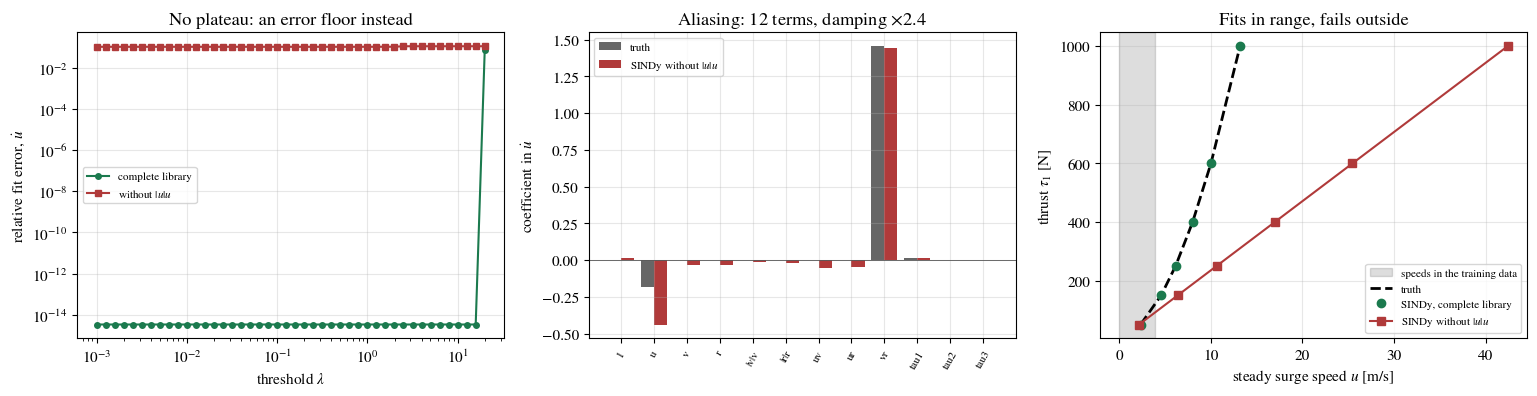

In [5]:
def plot_fail_library():
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.1))
    ax[0].loglog(lams, sw_full[:, 1], 'o-', color='C2', ms=4, label='complete library')
    ax[0].loglog(lams, sw_miss[:, 1], 's-', color='C3', ms=4, label=f'without ${DROPPED}$')
    ax[0].set(xlabel='threshold $\\lambda$', ylabel='relative fit error, $\\dot u$', title='No plateau: an error floor instead')
    ax[0].legend(fontsize=8)
    show = [n for n in kept if abs(Xi_m[kept.index(n), c_eq]) > 1e-9 or abs(Xi_true[names.index(n), c_eq]) > 0]
    xs = np.arange(len(show))
    ax[1].bar(xs - 0.2, [Xi_true[names.index(n), c_eq] for n in show], 0.4, color=fg(), alpha=0.6, label='truth')
    ax[1].bar(xs + 0.2, [Xi_m[kept.index(n), c_eq] for n in show], 0.4, color='C3', label=f'SINDy without ${DROPPED}$')
    ax[1].set_xticks(xs); ax[1].set_xticklabels(show, rotation=60, fontsize=8); ax[1].axhline(0, color=muted(), lw=0.6)
    ax[1].set(ylabel='coefficient in $\\dot u$', title=f'Aliasing: {active_m} terms, damping $\\times${Xi_m[kept.index("u"), c_eq]/Xi_true[names.index("u"), c_eq]:.1f}')
    ax[1].legend(fontsize=8)
    ax[2].axvspan(0, nu[:, 0].max(), color=muted(), alpha=0.2, label='speeds in the training data')
    ax[2].plot(u_true, THRUSTS, '--', color=fg(), lw=2, label='truth')
    ax[2].plot(u_full, THRUSTS, 'o', color='C2', label='SINDy, complete library')
    ax[2].plot(u_miss, THRUSTS, 's-', color='C3', label=f'SINDy without ${DROPPED}$')
    ax[2].set(xlabel='steady surge speed $u$ [m/s]', ylabel='thrust $\\tau_1$ [N]', title='Fits in range, fails outside')
    ax[2].legend(fontsize=8); plt.tight_layout()

save_dual(plot_fail_library, 'ed_fail_library', FIG)
plt.show()

Inside the visited speeds the aliased model and the truth nearly agree: on the vessel notebook's validation turning
circle (computed below) the path error after $40$~s is under a metre. At full thrust the aliased model predicts a
top speed of $25$~m/s where the truth is $10$: a linear damping cannot do the work of a quadratic drag once the speed
leaves the data. A plateau that never reaches the noise level, a structured residual and an extrapolation test are the
three things to check before believing a discovered equation.

In [6]:
tc = vessel.turning_circle(120.0, 30.0); _, Z_tc = vessel.simulate(tc, t_end=40.0, dt=0.02, p=p)
Z_m = rollout(Xi_m, keep, tc, 40.0)
print(f'validation turning circle, 40 s: path error of the aliased model {np.linalg.norm(Z_m[-1, :3] - Z_tc[-1, :3]):.2f} m')

validation turning circle, 40 s: path error of the aliased model 0.73 m


## 3. A hidden variable cannot be regressed around

Suppose sway is not measured. The library can only use $(u,r,\boldsymbol\tau)$, so the $\dot u$ equation loses its
dominant Coriolis term $vr$ and the $\dot r$ equation loses $uv$. The missing term is now a function of a state the
data does not contain: no column of any library on the measured variables can stand in for it, and the omitted-variable
formula has nothing to project onto.

In [7]:
keep_h = np.array([HIDDEN not in n for n in names]); obs = [n for n in names if HIDDEN not in n]
eq_h = [0, 2]                                                    # u-dot and r-dot are written in measured states
print('library on the measured states:', obs)
for lam in [LAM, 0.1, 1.0]:
    X_h = stlsq(Theta[:, keep_h], nudot[:, eq_h], lam)
    err_h = np.linalg.norm(Theta[:, keep_h] @ X_h - nudot[:, eq_h], axis=0)/np.linalg.norm(nudot[:, eq_h], axis=0)
    print(f'lambda = {lam:<5g}  relative fit error  u-dot {err_h[0]:.3f}   r-dot {err_h[1]:.3f}   '
          f'active terms {int((np.abs(X_h) > 1e-9).sum())}')
if AT_DEFAULTS:
    assert err_h[0] > 0.9

library on the measured states: ['1', 'u', 'r', '|u|u', '|r|r', 'ur', 'tau1', 'tau2', 'tau3']
lambda = 0.02   relative fit error  u-dot 0.993   r-dot 0.581   active terms 18
lambda = 0.1    relative fit error  u-dot 0.993   r-dot 0.581   active terms 18
lambda = 1      relative fit error  u-dot 0.993   r-dot 0.581   active terms 15


Ninety-nine percent of the surge acceleration (and $58\%$ of the yaw acceleration) is unexplained at every
threshold: on this maneuver almost all of
$\dot u$ is the Coriolis coupling to the hidden sway. The symptom differs from the incomplete library: the fit error is
not a modest floor but a large one, and no library refinement moves it. The remedies change the *state*, not the
library: measure $v$, augment the state with time-delayed copies of the measured signals (by Takens' theorem a delay
embedding can reconstruct the hidden coordinate), or learn coordinates and equation together (the SINDy autoencoder).

## 4. The regression fit is not the test

Back to the full library, now with noisy velocities and finite-difference derivatives as in section 4 of the vessel
notebook, threshold $\lambda=0.1$. Three numbers per model: the $R^2$ of the regression against the *noisy* derivative
(what the modeller sees), the $R^2$ against the clean derivative (what they would like to see), and the path error of
the integrated model on turning circles of increasing length.

In [8]:
horizon_truth = []
for T1, T3, TE in HORIZONS:
    tcf = vessel.turning_circle(T1, T3); horizon_truth.append((tcf, TE, vessel.simulate(tcf, t_end=TE, dt=0.02, p=p)[1]))
def r2(pred, target): return 1 - np.sum((pred - target)**2, 0)/np.sum((target - target.mean(0))**2, 0)
def coriolis_power(X_):
    # m11*xi(u,vr) + m22*xi(v,ur) + m33*xi(r,uv): zero for energy-conserving Coriolis terms
    m11, m22, m33 = np.diag(p.M())
    return m11*X_[names.index('vr'), 0] + m22*X_[names.index('ur'), 1] + m33*X_[names.index('uv'), 2]
rows = []
for lev in NOISE_LEVELS:
    rng = np.random.default_rng(0); nu_s = nu + lev/100*nu.std(0)*rng.standard_normal(nu.shape)
    Th_s, _ = library(nu_s, tau); nd_s = np.gradient(nu_s, dt, axis=0); X_f = stlsq(Th_s, nd_s, 0.1)
    pe = [float(np.linalg.norm(rollout(X_f, ALL, tcf, TE)[-1, :3] - Zt[-1, :3])) for tcf, TE, Zt in horizon_truth]
    rows.append((lev, r2(Th_s @ X_f, nd_s), r2(Theta @ X_f, nudot), int((np.abs(X_f) > 1e-9).sum()), pe, coriolis_power(X_f)))
print(f'Coriolis energy check, true model: {coriolis_power(Xi):+.1e}')
hdr = '  '.join(f'{TE:.0f} s' for _, _, TE in HORIZONS)
print(f'{"noise":>5} | {"R2 vs noisy (u,v,r)":>21} | {"R2 vs clean (u,v,r)":>22} | terms | path error at {hdr} | Coriolis check')
for lev, rn, rc, nt, pe, cp in rows:
    print(f'{lev:4d}% | {rn[0]:6.3f} {rn[1]:6.3f} {rn[2]:6.3f} | {rc[0]:6.4f} {rc[1]:6.4f} {rc[2]:6.4f} | {nt:5d} | '
          + '  '.join(f'{e:7.2f} m' for e in pe) + f' | {cp:+7.2f}')
if AT_DEFAULTS:
    assert rows[0][1][1] < 0.1 and rows[-1][4][-1] > 10*rows[-1][4][0]

Coriolis energy check, true model: +2.2e-13
noise |   R2 vs noisy (u,v,r) |    R2 vs clean (u,v,r) | terms | path error at 40 s  120 s  200 s | Coriolis check
   5% |  0.202  0.040  0.046 | 0.9985 0.9779 0.9900 |    38 |    0.31 m     3.62 m    10.71 m |  +10.50
  10% |  0.056  0.009  0.011 | 0.9837 0.8975 0.9533 |    39 |    1.35 m    11.04 m    40.68 m |  +21.20
  20% |  0.012  0.002  0.003 | 0.8750 0.7490 0.8439 |    39 |    4.62 m    38.15 m   128.20 m |  +26.30


Read the table from left to right. The regression $R^2$ against the noisy derivative is close to zero, yet the
same models explain the clean dynamics with $R^2$ between $0.75$ and $0.999$: differentiated noise dominates the target, so a low $R^2$ does
not mean a bad model, just as $R^2=0.989$ in section 1 did not mean a good one. The rollout error grows by an order of
magnitude when the horizon goes from $40$ to $200$~s: a validation horizon is part of the claim. And the energy check
exposes what the coefficients hide. In the true model the Coriolis terms do no work,
$m_{11}\xi_{u,vr}+m_{22}\xi_{v,ur}+m_{33}\xi_{r,uv}=0$ (the matrix $\mathbf C(\boldsymbol\nu)$ is skew-symmetric); in the
noisy models that combination is nonzero and grows with the noise, a spurious source of energy proportional to $uvr$.
The vessel's strong drag keeps these models bounded; on a lightly damped system the same violation is how discovered
models blow up, and it is why constrained SINDy imposes the skew-symmetry as a linear equality on $\boldsymbol\Xi$.

**Takeaways.** Discovery fails quietly. An incomplete library aliases the missing physics into wrong coefficients with
a high $R^2$; a hidden state leaves a large error floor that no library can remove; noisy derivatives make the
regression $R^2$ meaningless in both directions. The diagnostics that do work are the ones that test the *equation*:
a plateau that reaches the noise level, residuals without structure, extrapolation and long-horizon rollouts, and
physical checks such as energy conservation.